# 01 — Setup and data audit

## Goal of this step

Inspect the real CSV before changing it. Find hidden missing values and understand what one row and the target mean.

## Why this matters

An audit is like checking ingredients before cooking: a wrong ingredient can spoil every later step. A dtype describes how Python stores a column, not necessarily what that column means.

Find the project root and import display tools. Reusable logic lives in src.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np  # noqa: F401
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
assert Path(sys.executable).resolve().is_relative_to(ROOT / ".venv"), "Select the project venv kernel."
%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 4)


Load with pd.read_csv through src, then inspect a few rows and the shape.

In [2]:
from src.data import load_raw, audit
df = load_raw()
report = audit(df)
display(df.head())
display(pd.Series(report['shape'], index=['rows', 'columns']))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


rows       7043
columns      21
dtype: int64

**Interpretation:** Each of the 7,043 rows represents a customer, with 21 columns including the target and ID.

Compare dtype, missing values, and unique counts. A value can look empty yet still be a string.

In [3]:
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique': df.nunique(dropna=False)}))
display(pd.Series({'duplicate rows': report['duplicate_rows'], 'duplicate IDs': report['duplicate_ids']}))

,dtype,missing,unique
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


duplicate rows    0
duplicate IDs     0
dtype: int64

**Interpretation:** TotalCharges is stored as text (object/string depending on pandas version); isna alone misses whitespace blanks.

Coercion is a diagnostic here: identify text that cannot be interpreted as a number, without changing the input.

In [4]:
charges = pd.to_numeric(df['TotalCharges'], errors='coerce')
display(df.loc[charges.isna(), ['tenure', 'MonthlyCharges', 'TotalCharges']])
display(pd.Series({k: report[k] for k in ['total_charges_blank', 'total_charges_numeric_missing']}))

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,
3331,0,19.85,
3826,0,25.35,
4380,0,20.00,
5218,0,19.70,
6670,0,73.35,


total_charges_blank              11
total_charges_numeric_missing    11
dtype: int64

**Interpretation:** There are 11 blank charges, all at tenure zero: new customers have not accumulated a bill.

Count both labels and plot their share to understand imbalance.

,customers
Churn,
No,5174
Yes,1869


,share
Churn,
No,0.73463
Yes,0.26537


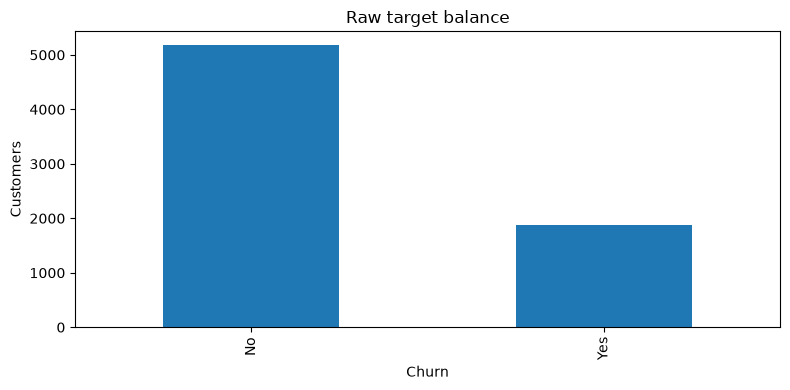

In [5]:
display(df['Churn'].value_counts().to_frame('customers'))
display(df['Churn'].value_counts(normalize=True).to_frame('share'))
df['Churn'].value_counts().plot.bar(title='Raw target balance', ylabel='Customers')
plt.tight_layout()
plt.show()

**Interpretation:** Roughly 26.5% churn; predicting No for everyone can look accurate while missing every churner.

## Common mistakes

- Treating whitespace as a real charge.
- Assuming a text dtype means a categorical feature.
- Training before checking the target and ID.

## Key takeaways

- The raw dataset has 7,043 customers and 21 columns.
- Eleven blank TotalCharges entries need an explicit rule.
- Churn is imbalanced, so accuracy alone will be insufficient.

## Next step

02_data_cleaning.ipynb: turn the audited rules into tested functions.